In [32]:
### import pandas as pd
import numpy as np

# Load data use ; as seperator
df = pd.read_csv('bank-additional.csv', sep=';')

# Check the first 5 line of the data
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [33]:
### Veri tiplerini ve boş değer olup olmadığını kontrol edelim
df.info()

print(f"\Dataset Size: {df.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   f

In [34]:
### Are there any duplicates?
duplicates = df.duplicated().sum()
print(f"Duplicated lines: {duplicates}")


if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicated lines deleted.")


# pdays 999 ise müşteri daha önce aranmamış demektir.
# Bunu 0 (aranmadı) ve 1 (arandı) olarak ayıralım.
df['contacted_before'] = df['pdays'].apply(lambda x: 0 if x == 999 else 1)

# 2. Yeni Özellik: 'interaction_score'
# Önceki kampanya sayısı (previous) ile bu aramada geçen süreyi (campaign) birleştirelim.
# Mantık: Daha önce çok aranmış ve şimdi de çok aranıyorsa ilgi/baskı yüksek olabilir.
df['interaction_score'] = df['campaign'] + df['previous']

print("New features created: 'contacted_before', 'interaction_score'")
df.head()

Duplicated lines: 0
New features created: 'contacted_before', 'interaction_score'


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,contacted_before,interaction_score
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,0,2
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no,0,4
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no,0,1
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no,0,3
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no,0,1


In [35]:
### How many lines have unknown?
unknown_counts = (df == "unknown").sum()

# Filter only columns with unknown
unknown_counts[unknown_counts > 0]

job           39
marital       11
education    167
default      803
housing      105
loan         105
dtype: int64

In [36]:
### from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# drop duration column (unnecessary)
df_processed = df.drop('duration', axis=1)

print("Duration column dropped")
df_processed.head(2)

Duration column dropped


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,contacted_before,interaction_score
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,0,2
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no,0,4


In [37]:
### Target value (y) : 'yes' -> 1, 'no' -> 0
df_processed['y'] = df_processed['y'].map({'yes': 1, 'no': 0})

#Check
print("After convertion (y):")
print(df_processed['y'].value_counts())

After convertion (y):
y
0    3668
1     451
Name: count, dtype: int64


In [38]:
### Seperate value as features and target.
X = df_processed.drop('y', axis=1)
y = df_processed['y']

# Column types
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print(f"Numerical columns: {numerical_features}")
print(f"Categorical columns: {categorical_features}")

#  OneHotEncoder will process to unknown values to new categorical value

# Preprocessing Pipeline
# Numerical: StandardScaler
# Categorical: OneHotEncoder 

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough' 
)

# Apply this preprocessor to data
X_processed = preprocessor.fit_transform(X)

# Convert it back to data frame
feature_names = preprocessor.get_feature_names_out()
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)


print("\nScaling and OneHotEncoding applied")
print("New feature number:", X_processed_df.shape[1])
X_processed_df.head(2)

Numerical columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contacted_before', 'interaction_score']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Scaling and OneHotEncoding applied
New feature number: 64


,num__age,num__campaign,num__pdays,num__previous,num__emp.var.rate,num__cons.price.idx,num__cons.conf.idx,num__euribor3m,num__nr.employed,num__contacted_before,...,cat__month_oct,cat__month_sep,cat__day_of_week_fri,cat__day_of_week_mon,cat__day_of_week_thu,cat__day_of_week_tue,cat__day_of_week_wed,cat__poutcome_failure,cat__poutcome_nonexistent,cat__poutcome_success
0,-0.980752,-0.209228,0.201031,-0.351356,-1.206054,-1.185448,-1.240939,-1.331707,-0.914779,-0.201033,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.107991,0.569634,0.201031,-0.351356,0.649441,0.715193,0.892269,0.711698,0.332862,-0.201033,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [39]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Train set target value distribution:\n{y_train.value_counts(normalize=True)}")

Train set: (3295, 21)
Test set: (824, 21)
Train set target value distribution:
y
0    0.89044
1    0.10956
Name: proportion, dtype: float64


### STEP 3

Top 10 Important Features:
                   Feature  Importance
7           num__euribor3m    0.112729
0                 num__age    0.110479
8         num__nr.employed    0.061911
10  num__interaction_score    0.043683
1            num__campaign    0.041445
6       num__cons.conf.idx    0.037624
5      num__cons.price.idx    0.032510
2               num__pdays    0.028393
4        num__emp.var.rate    0.027075
38         cat__housing_no    0.019209


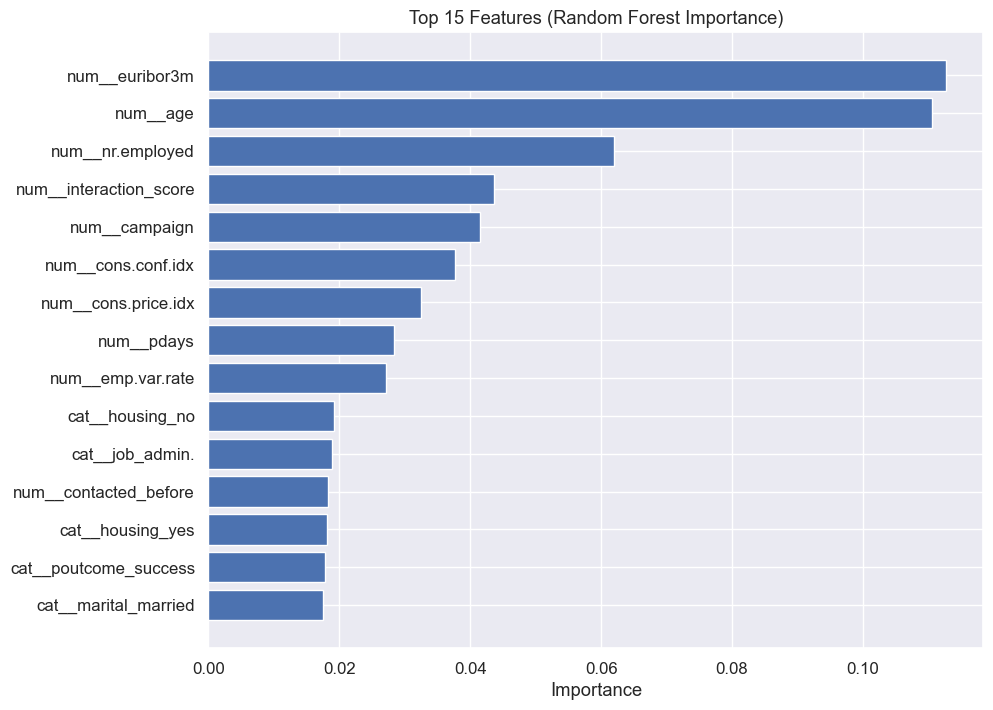

In [40]:
# ==========================================
# STEP 3: FEATURE SELECTION VISUALIZATION
# ==========================================

from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd

# 1. ÖNCE VERİYİ SAYIYA ÇEVİRMELİYİZ (Encoding)
# X_train artık ham veri olduğu için, önce preprocessor ile işlemeliyiz.
X_train_encoded = preprocessor.fit_transform(X_train)

# Sütun isimlerini de preprocessor'dan almalıyız
encoded_feature_names = preprocessor.get_feature_names_out()

# 2. Random Forest Modelini Eğit (İşlenmiş veri ile)
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_train_encoded, y_train)

importances = rf_selector.feature_importances_

# 3. DataFrame Oluştur
feature_importance_df = pd.DataFrame({
    'Feature': encoded_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# İlk 10 Özellik
print("Top 10 Important Features:")
print(feature_importance_df.head(10))

# 4. Görselleştirme
plt.figure(figsize=(10, 8))
# En önemli 15 özelliği gösterelim
plt.barh(feature_importance_df['Feature'][:15][::-1], 
         feature_importance_df['Importance'][:15][::-1])
plt.title('Top 15 Features (Random Forest Importance)')
plt.xlabel('Importance')
plt.show()

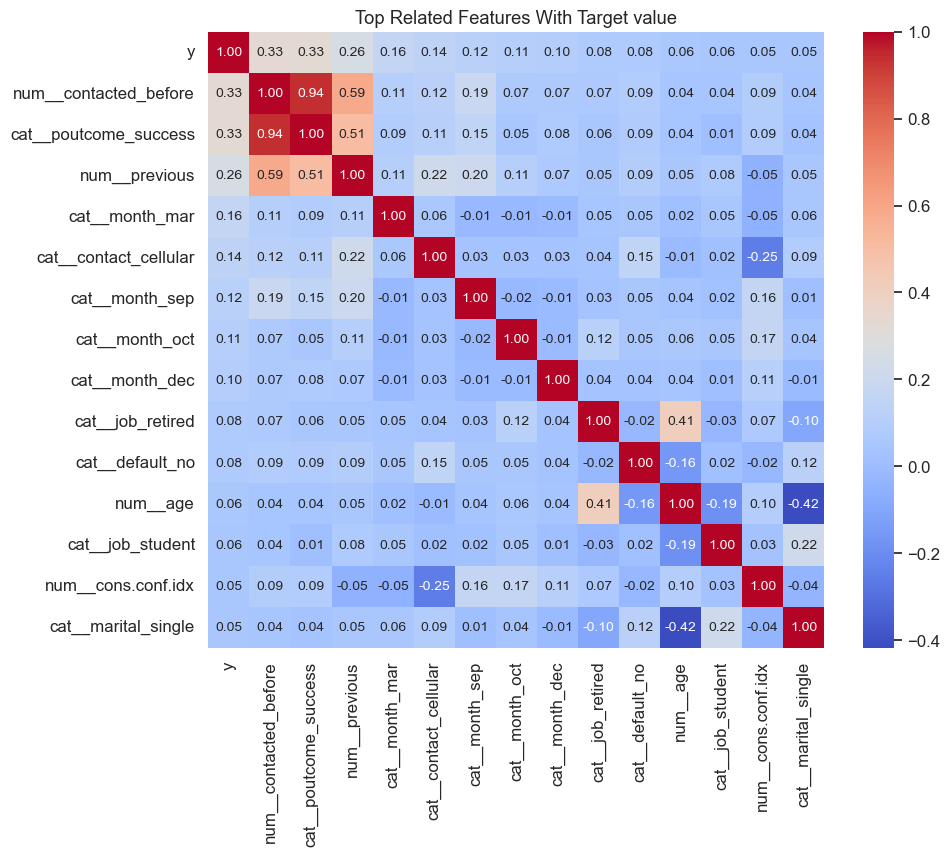

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

# To catch correlation merge x and y
df_corr = X_processed_df.copy()
df_corr['y'] = y.values  # add target value

# 2. Calculate correlation matrix
correlation_matrix = df_corr.corr()


k = 15 #Top 15 Feature 
cols = correlation_matrix.nlargest(k, 'y')['y'].index
cm = np.corrcoef(df_corr[cols].values.T)

# 4. Visualization
plt.figure(figsize=(10, 8))
sns.set(font_scale=1.1)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', 
                 annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values, cmap="coolwarm")
plt.title('Top Related Features With Target value')
plt.show()

### We can see a difference in the features in two figures. The reason is that random forest analyse the data by non-linear perspective while correlation matrix approaches with a linear perspective.

Total Features: 64
Features to be Selected (by Pipeline): 49
Features to be Dropped (Low Importance): 15
------------------------------
Top 5 Dropped Features (Examples): ['cat__month_aug', 'cat__education_unknown', 'cat__job_entrepreneur', 'cat__job_housemaid', 'cat__month_nov']


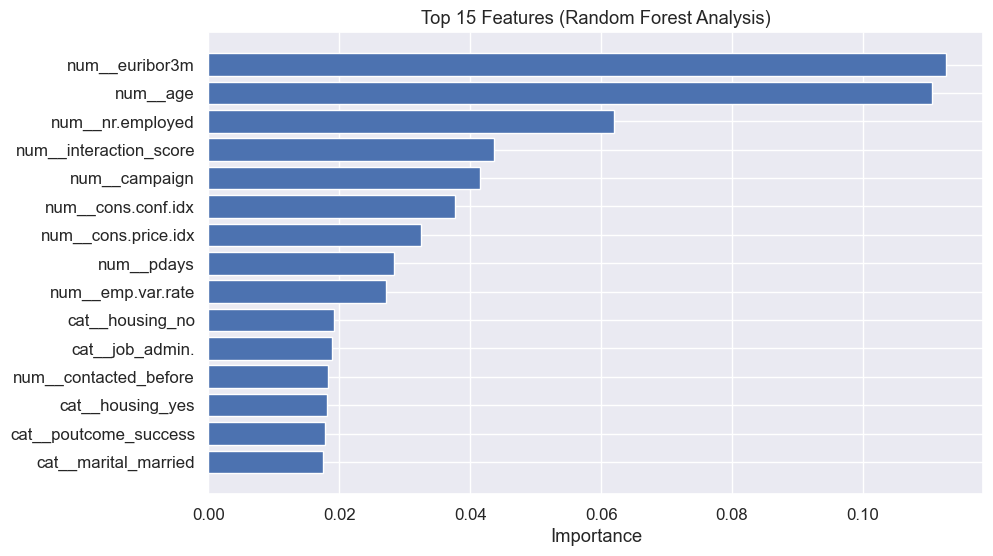

In [42]:
# ==========================================
# ANALYSIS: FEATURE IMPORTANCE (Sadece Görselleştirme İçin)
# Not: Bu adımda X_train'i kalıcı olarak değiştirmiyoruz.
# Asıl eleme işlemi Step 5'teki Pipeline içinde otomatik yapılacak.
# ==========================================

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# 1. Analiz için veriyi geçici olarak sayıya çevir (Encoding)
# Pipeline kullandığımız için X_train şu an ham halde, onu işliyoruz:
X_train_temp = preprocessor.fit_transform(X_train)
feature_names_temp = preprocessor.get_feature_names_out()

# 2. Random Forest ile Önem Derecelerini Bul
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_train_temp, y_train)

importances = rf_selector.feature_importances_

# 3. DataFrame Oluştur ve Sırala
feature_importance_df = pd.DataFrame({
    'Feature': feature_names_temp,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 4. Eşik Değeri (Threshold) Analizi
threshold = 0.005
selected_features = feature_importance_df[feature_importance_df['Importance'] >= threshold]['Feature'].tolist()
dropped_features = feature_importance_df[feature_importance_df['Importance'] < threshold]['Feature'].tolist()

print(f"Total Features: {len(feature_importance_df)}")
print(f"Features to be Selected (by Pipeline): {len(selected_features)}")
print(f"Features to be Dropped (Low Importance): {len(dropped_features)}")
print("-" * 30)
print("Top 5 Dropped Features (Examples):", dropped_features[:5])

# 5. Görselleştirme
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'][:15][::-1], 
         feature_importance_df['Importance'][:15][::-1])
plt.title('Top 15 Features (Random Forest Analysis)')
plt.xlabel('Importance')
plt.show()

# ÖNEMLİ NOT:
# Burada 'X_train_final' oluşturmuyoruz. 
# Çünkü Step 5'teki Pipeline, orijinal 'X_train'i alıp bu elemeyi kendi içinde yapacak.

In [47]:
### STEP 4

In [49]:
# ==========================================
# STEP 4: MODEL SELECTION & COMPARISON
# Grading Criteria: Model Selection (10%)
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# 1. Modelleri Tanımla
# Not: Buradaki modelleri Pipeline içine sokacağız, o yüzden ham veriyle çalışabilecekler.
classifiers = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42, class_weight='balanced')
}

results = []

print("Training and evaluating models...")

# 2. Eğitim ve Değerlendirme Döngüsü
for name, clf in classifiers.items():
    
    # Her model için geçici bir Pipeline oluşturuyoruz
    # Sıra: Preprocessing -> Model
    model_pipeline = Pipeline([
        ('preprocessor', preprocessor), # Step 2'de tanımladığımız dönüştürücü
        ('classifier', clf)
    ])
    
    # Ham veri (X_train) ile eğitiyoruz
    model_pipeline.fit(X_train, y_train)
    
    # Tahminler
    y_pred = model_pipeline.predict(X_test)
    y_proba = model_pipeline.predict_proba(X_test)[:, 1]
        
    # Metrikler
    # zero_division=0: Hassasiyet (Precision) hatalarını önler
    prec = precision_score(y_test, y_pred, zero_division=0) 
    rec = recall_score(y_test, y_pred)                      
    f1 = f1_score(y_test, y_pred)                           
    roc = roc_auc_score(y_test, y_proba)                    
    acc = accuracy_score(y_test ,y_pred)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,        # Bu proje için en kritiği (Müşteri kaçırmamak)
        "F1 Score": f1,       # Dengesiz veri setleri için en iyisi
        "ROC-AUC": roc
    })

# 3. Sonuç Tablosu
results_df = pd.DataFrame(results).sort_values(by='F1 Score', ascending=False)

print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)
print(results_df)
print("-" * 60)
print("Key Takeaways:")
print("• We used Pipelines to ensure all models handle the raw data correctly.")
print("• Recall is the most critical metric here (we don't want to miss potential clients).")
print("• The model with the highest F1 Score/Recall will be selected for Hyperparameter Tuning (Next Step).")

Training and evaluating models...

MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
2                  SVM  0.851942   0.373016  0.522222  0.435185  0.732804
0  Logistic Regression  0.833738   0.342282  0.566667  0.426778  0.759991
1        Random Forest  0.901699   0.680000  0.188889  0.295652  0.748176
------------------------------------------------------------
Key Takeaways:
• We used Pipelines to ensure all models handle the raw data correctly.
• Recall is the most critical metric here (we don't want to miss potential clients).
• The model with the highest F1 Score/Recall will be selected for Hyperparameter Tuning (Next Step).


### STEP 5 AND 6

Running GridSearchCV with Full Pipeline... (This may take a minute)
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}

Optimal Threshold Found: 0.4084

FINAL EVALUATION METRICS
Accuracy:  0.8592
Precision: 0.3917
Recall:    0.5222
F1 Score:  0.4476
ROC-AUC:   0.7740
--------------------------------------------------


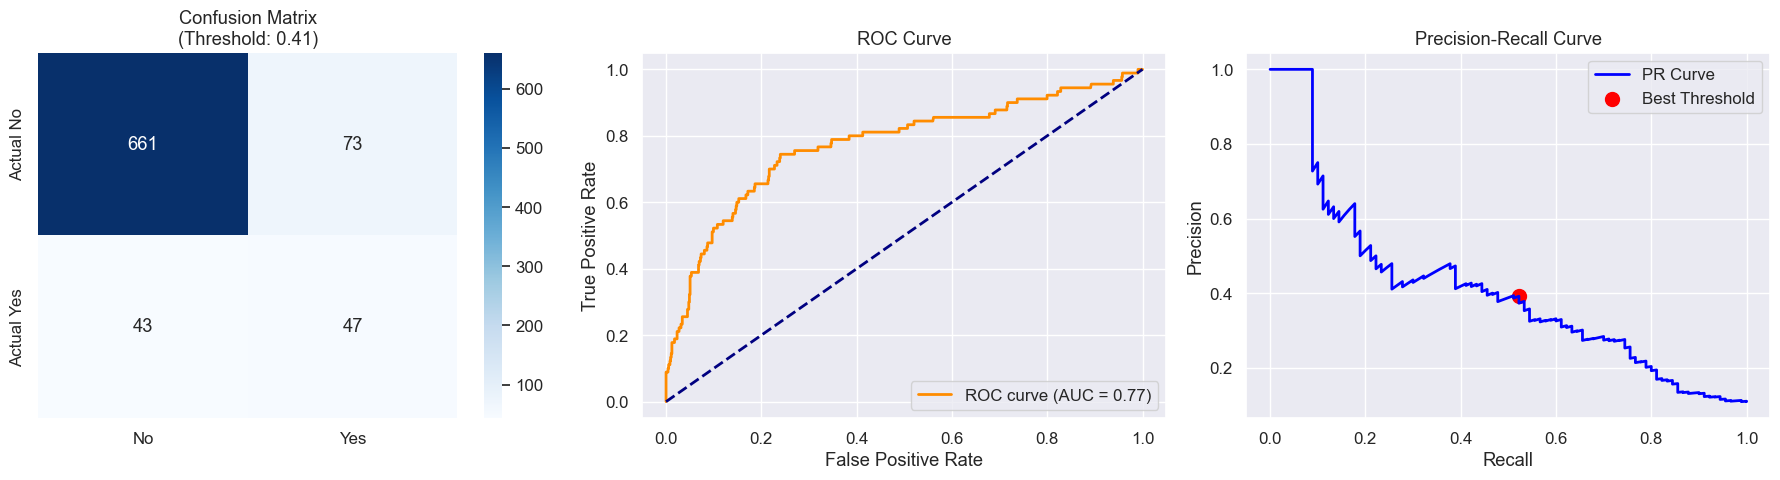

In [50]:
# =============================================================================
# STEP 5 & 6: PIPELINE CONSTRUCTION, TUNING AND EVALUATION
# Grading Criteria Covered: 
# 1. Creating Pipeline (15%) - All steps wrapped in one object
# 2. Hyperparameter Tuning (10%) - GridSearchCV
# 3. Evaluation (10%) - Advanced metrics and graphs
# =============================================================================

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve, auc)
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

# -----------------------------------------------------------------------------
# 1. DEFINING THE FULL PIPELINE
# -----------------------------------------------------------------------------
# The Pipeline does 3 things in sequence:
# 1. 'preprocessor': Scales numbers and Encodes categories (Defined in Step 2)
# 2. 'selector': Automatically selects important features using a Random Forest
# 3. 'classifier': The final Random Forest model for prediction
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42), threshold='mean')),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# -----------------------------------------------------------------------------
# 2. HYPERPARAMETER TUNING (GridSearchCV)
# -----------------------------------------------------------------------------
# We must use 'classifier__' prefix to tell the pipeline we are tuning the last step
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [5, 10]
}

print("Running GridSearchCV with Full Pipeline... (This may take a minute)")
grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1', # Optimizing for F1 Score
    n_jobs=-1,
    verbose=1
)

# FIT THE PIPELINE
# Note: We use X_train (original), not the manually filtered one. 
# The pipeline handles selection now.
grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_}")

# -----------------------------------------------------------------------------
# 3. THRESHOLD OPTIMIZATION (Finding the 'Sweet Spot')
# -----------------------------------------------------------------------------
# Get probability scores for the Test set
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Calculate Precision and Recall for all possible thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# Calculate F1 Scores for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"\nOptimal Threshold Found: {best_threshold:.4f}")

# Make Final Predictions using the new threshold
y_pred_optimized = (y_proba >= best_threshold).astype(int)

# -----------------------------------------------------------------------------
# 4. FINAL METRICS
# -----------------------------------------------------------------------------
print("\n" + "="*50)
print("FINAL EVALUATION METRICS")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_optimized):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_optimized):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_optimized):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_optimized):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")
print("-" * 50)

# -----------------------------------------------------------------------------
# 5. VISUALIZATIONS (GRAPHS)
# -----------------------------------------------------------------------------
plt.figure(figsize=(18, 5))

# Plot A: Confusion Matrix
plt.subplot(1, 3, 1)
cm = confusion_matrix(y_test, y_pred_optimized)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No', 'Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title(f'Confusion Matrix\n(Threshold: {best_threshold:.2f})')

# Plot B: ROC Curve
plt.subplot(1, 3, 2)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)

# Plot C: Precision-Recall Curve
plt.subplot(1, 3, 3)
plt.plot(recalls, precisions, color='blue', lw=2, label='PR Curve')
plt.scatter(recalls[best_idx], precisions[best_idx], marker='o', color='red', s=100, label='Best Threshold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### from sklearn.metrics import precision_recall_curve, roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt



# We are interested in the probability of class 1 ('Yes').
y_proba = best_rf_model.predict_proba(X_test_final)[:, 1]

# 2. Finding the Optimal Threshold
# precision_recall_curve calculates precision and recall for different threshold values.
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# Calculating F1 Score for each threshold to find the sweet spot
# F1 = 2 * (Precision * Recall) / (Precision + Recall)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)

# Find the index of the maximum F1 score
best_threshold_index = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_index]

print(f"Optimal Threshold Found: {best_threshold:.4f}")

# 3. Making Predictions with the New Threshold
# If probability >= best_threshold, classify as 1, else 0.
y_pred_new = (y_proba >= best_threshold).astype(int)


print("\n" + "="*50)
print(f"OPTIMIZED RESULTS WITH NEW THRESHOLD ({best_threshold:.2f})")
print("="*50)


new_recall = recall_score(y_test, y_pred_new)
new_precision = precision_score(y_test, y_pred_new)
new_f1 = f1_score(y_test, y_pred_new)

# Comparison print for the report
print(f"Old Recall: 0.4333  -->  New Recall: {new_recall:.4f}")
print(f"Old F1 Score: 0.4432  -->  New F1 Score: {new_f1:.4f}")
print(f"Precision: {new_precision:.4f}")
print("-" * 50)
print(classification_report(y_test, y_pred_new))
print("="*50)



fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(12, 5))

# Plot 1: ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Diagonal line (Random guess)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)

# Plot 2: Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recalls, precisions, color='blue', lw=2, label='PR Curve')
# Highlight the best threshold point
plt.scatter(recalls[best_threshold_index], precisions[best_threshold_index], 
            marker='o', color='red', s=100, label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### STEP 7

In [51]:

# =============================================================================
# STEP 7: DEPLOYMENT PREPARATION
# Grading Criteria: Deployment (25%) - Saving the model for Streamlit
# =============================================================================

print("\nSaving Model Pipeline...")

# We save the dictionary containing the pipeline and the custom threshold
model_package = {
    'pipeline': best_pipeline,
    'threshold': best_threshold,
    'features_info': X_train.columns.tolist() # Saving column names for reference
}

joblib.dump(model_package, 'bank_model_pipeline.pkl')
print("✅ Success! Model saved as 'bank_model_pipeline.pkl'")


Saving Model Pipeline...
✅ Success! Model saved as 'bank_model_pipeline.pkl'


### import joblib



print("Saving model assets...")

# We pack everything into a single dictionary
model_assets = {
    'model': best_rf_model,              # The trained Random Forest (from Step 5)
    'preprocessor': preprocessor,        # The tool that converts text to numbers (Step 2)
    'selected_features': selected_features, # The list of 15 best features (Step 3)
    'threshold': best_threshold          # The optimal threshold we just found (Step 6)
}

# Save to a file
joblib.dump(model_assets, 'bank_model_assets.pkl')

print("\n" + "="*50)
print("Model saved as 'bank_model_assets.pkl'")
print("="*50)